Paths and reusable definitions were refactored. Stored outputs below are historical, not a fresh execution. See `docs/WORKFLOW.md` at the repository root before rerunning; several stages overwrite results or append Optuna trials.


In [ ]:
# Locate this checkout from the repository root or any notebook subdirectory.
from pathlib import Path
import sys

_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
              if (p / "src" / "steam_recommender" / "paths.py").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside the repository checkout.")
sys.path.insert(0, str(_root / "src"))
from steam_recommender import paths as _paths
if Path(_paths.__file__).resolve() != (_root / "src/steam_recommender/paths.py").resolve():
    raise RuntimeError("A different checkout is cached; restart the kernel.")
from steam_recommender.paths import project_root, project_path


In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ROOT_DIR = project_root()

RAW_DATA_DIR = project_path("data/raw")
FILTERED_DATA_DIR = project_path("data/processed")

EDA_DIR = project_path("results/eda")
FIGURES_DIR = EDA_DIR / "figures_raw"
RESULTS_DIR = EDA_DIR / "results_raw"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

RAW_USERS_ITEMS_PATH = RAW_DATA_DIR / "users_items.csv"

print("ROOT_DIR:", ROOT_DIR)
print("RAW_USERS_ITEMS_PATH:", RAW_USERS_ITEMS_PATH)
print("File exists:", RAW_USERS_ITEMS_PATH.exists())

ROOT_DIR: D:\Studiowe\Licencjat\modele
RAW_USERS_ITEMS_PATH: D:\Studiowe\Licencjat\modele\data_raw\users_items.csv
File exists: True


In [3]:
users_items_raw = pd.read_csv(RAW_USERS_ITEMS_PATH)

print(users_items_raw.shape)
users_items_raw.head()
users_items_raw.info()

(5153209, 4)
<class 'pandas.DataFrame'>
RangeIndex: 5153209 entries, 0 to 5153208
Data columns (total 4 columns):
 #   Column            Dtype
---  ------            -----
 0   user_id           str  
 1   item_id           int64
 2   item_name         str  
 3   playtime_forever  int64
dtypes: int64(2), str(2)
memory usage: 157.3 MB


In [4]:
n_interactions = len(users_items_raw)
n_users = users_items_raw["user_id"].nunique()
n_items = users_items_raw["item_id"].nunique()

density = n_interactions / (n_users * n_items)

basic_stats_raw = pd.DataFrame({
    "metric": [
        "interactions",
        "users",
        "items",
        "matrix_density",
    ],
    "value": [
        n_interactions,
        n_users,
        n_items,
        density,
    ],
})

basic_stats_raw


,metric,value
0,interactions,5.153209e+06
1,users,7.091200e+04
2,items,1.097800e+04
3,matrix_density,6.619646e-03


In [5]:
basic_stats_raw.to_csv(
    RESULTS_DIR / "basic_stats_raw.csv",
    index=False,
)

In [6]:
missing_values_raw = (
    users_items_raw
    .isna()
    .sum()
    .reset_index()
    .rename(columns={"index": "column", 0: "missing_count"})
)

missing_values_raw["missing_share"] = (
    missing_values_raw["missing_count"] / len(users_items_raw)
)

missing_values_raw


,column,missing_count,missing_share
0,user_id,0,0.0
1,item_id,0,0.0
2,item_name,0,0.0
3,playtime_forever,0,0.0


In [7]:
missing_values_raw.to_csv(
    RESULTS_DIR / "missing_values_raw.csv",
    index=False,
)

In [8]:
user_interaction_counts_raw = (
    users_items_raw
    .groupby("user_id")
    .size()
    .rename("n_interactions")
)

user_interaction_counts_raw.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])

count    70912.000000
mean        72.670479
std        134.056122
min          1.000000
1%           1.000000
5%           2.000000
25%         14.000000
50%         40.000000
75%         88.000000
95%        237.450000
99%        489.890000
max       7762.000000
Name: n_interactions, dtype: float64

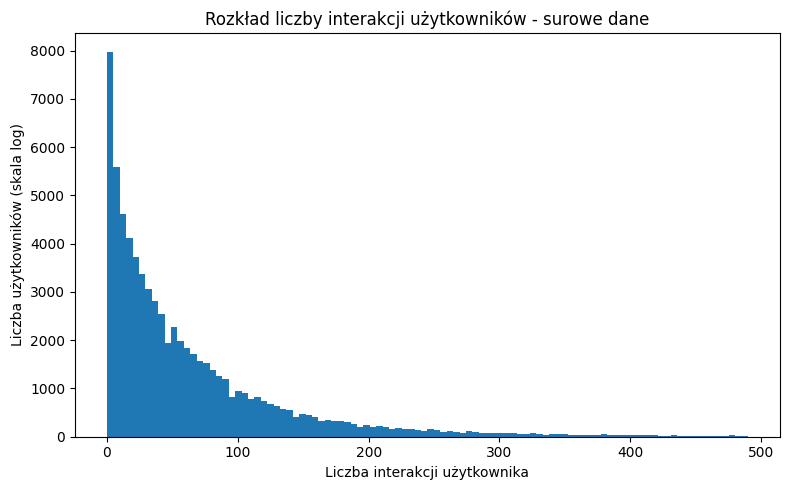

In [16]:
plt.figure(figsize=(8, 5))
plt.hist(user_interaction_counts_raw, bins=100, range=(0, user_interaction_counts_raw.quantile(0.99)))
plt.xlabel("Liczba interakcji użytkownika")
plt.ylabel("Liczba użytkowników (skala log)")
plt.title("Rozkład liczby interakcji użytkowników - surowe dane")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "raw_user_interaction_counts_hist.png", dpi=300)
plt.show()

In [10]:
zero_playtime_share_raw = (users_items_raw["playtime_forever"] == 0).mean()
positive_playtime_raw = users_items_raw.loc[
    users_items_raw["playtime_forever"] > 0,
    "playtime_forever"
]

print(f"Udział interakcji z playtime_forever = 0: {zero_playtime_share_raw:.2%}")
positive_playtime_raw.describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99, 0.999])

Udział interakcji z playtime_forever = 0: 36.25%


count    3.285246e+06
mean     1.555251e+03
std      6.721032e+03
min      1.000000e+00
50%      2.050000e+02
75%      8.080000e+02
90%      2.774000e+03
95%      6.029000e+03
99%      2.570755e+04
99.9%    8.944885e+04
max      6.427730e+05
Name: playtime_forever, dtype: float64

Liczba interakcji z playtime_forever = 0: 1,867,963
Udział interakcji z playtime_forever = 0: 36.25%


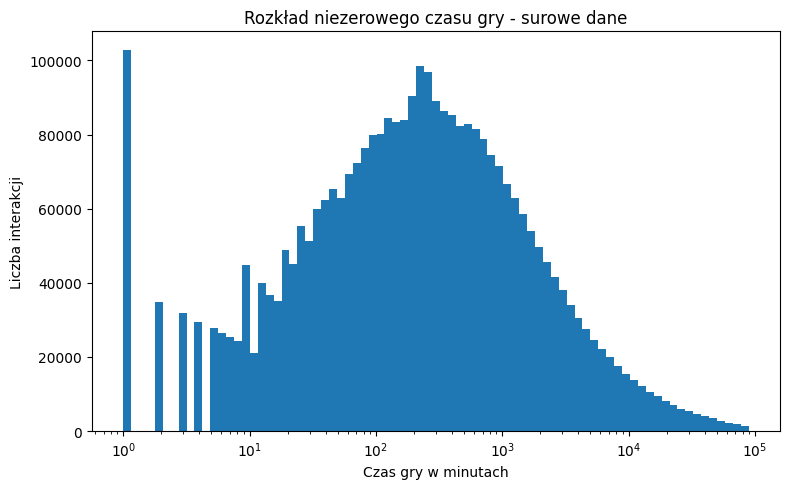

In [23]:
playtime_raw = users_items_raw["playtime_forever"]

zero_playtime_count_raw = (playtime_raw == 0).sum()
zero_playtime_share_raw = (playtime_raw == 0).mean()

positive_playtime_raw = playtime_raw[playtime_raw > 0]

print(f"Liczba interakcji z playtime_forever = 0: {zero_playtime_count_raw:,}")
print(f"Udział interakcji z playtime_forever = 0: {zero_playtime_share_raw:.2%}")

bins = np.logspace(
    np.log10(positive_playtime_raw.min()),
    np.log10(positive_playtime_raw.quantile(0.999)),
    80
)

plt.figure(figsize=(8, 5))
plt.hist(positive_playtime_raw, bins=bins)

plt.xscale("log")
plt.xlabel("Czas gry w minutach")
plt.ylabel("Liczba interakcji")
plt.title("Rozkład niezerowego czasu gry - surowe dane")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "raw_positive_playtime_logscale_hist.png", dpi=300)
plt.show()

In [12]:
small_playtime_counts_with_zero = (
    users_items_raw.loc[
        users_items_raw["playtime_forever"] <= 30,
        "playtime_forever"
    ]
    .value_counts()
    .sort_index()
)

small_playtime_counts_with_zero.head(31)

playtime_forever
0     1867963
1      102730
2       34770
3       31905
4       29438
5       27922
6       26534
7       25359
8       24227
9       22748
10      22179
11      21079
12      20152
13      19752
14      18599
15      18228
16      17699
17      17305
18      16803
19      16267
20      15923
21      15459
22      14954
23      14753
24      14314
25      13972
26      13730
27      13399
28      13152
29      12900
30      12738
Name: count, dtype: int64

In [13]:
MIN_INTERACTIONS = 5
PLAYTIME_CAP = 120_000

raw_interactions = len(users_items_raw)
raw_users = users_items_raw["user_id"].nunique()
raw_items = users_items_raw["item_id"].nunique()

# Etap 1: clip playtime
users_items_clipped = users_items_raw.copy()
users_items_clipped["playtime_forever"] = users_items_clipped["playtime_forever"].clip(
    upper=PLAYTIME_CAP
)

# Etap 2: filtr itemów
item_counts = users_items_clipped["item_id"].value_counts()
valid_items = item_counts[item_counts >= MIN_INTERACTIONS].index

after_item_filter = users_items_clipped[
    users_items_clipped["item_id"].isin(valid_items)
].copy()

# Etap 3: filtr użytkowników po filtrze itemów
user_counts_after_item_filter = after_item_filter["user_id"].value_counts()
valid_users = user_counts_after_item_filter[
    user_counts_after_item_filter >= MIN_INTERACTIONS
].index

after_user_filter = after_item_filter[
    after_item_filter["user_id"].isin(valid_users)
].copy()

filtering_summary = pd.DataFrame({
    "stage": [
        "raw",
        "after_playtime_clip",
        "after_item_filter_min_5",
        "after_user_filter_min_5",
    ],
    "interactions": [
        len(users_items_raw),
        len(users_items_clipped),
        len(after_item_filter),
        len(after_user_filter),
    ],
    "users": [
        users_items_raw["user_id"].nunique(),
        users_items_clipped["user_id"].nunique(),
        after_item_filter["user_id"].nunique(),
        after_user_filter["user_id"].nunique(),
    ],
    "items": [
        users_items_raw["item_id"].nunique(),
        users_items_clipped["item_id"].nunique(),
        after_item_filter["item_id"].nunique(),
        after_user_filter["item_id"].nunique(),
    ],
})

filtering_summary["interactions_share_of_raw"] = filtering_summary["interactions"] / raw_interactions
filtering_summary["users_share_of_raw"] = filtering_summary["users"] / raw_users
filtering_summary["items_share_of_raw"] = filtering_summary["items"] / raw_items

filtering_summary

,stage,interactions,users,items,interactions_share_of_raw,users_share_of_raw,items_share_of_raw
0,raw,5153209,70912,10978,1.000000,1.000000,1.000000
1,after_playtime_clip,5153209,70912,10978,1.000000,1.000000,1.000000
2,after_item_filter_min_5,5149512,70912,9198,0.999283,1.000000,0.837858
3,after_user_filter_min_5,5132610,62944,9198,0.996003,0.887635,0.837858


In [14]:
filtering_summary.to_csv(
    RESULTS_DIR / "filtering_summary_raw_to_filtered.csv",
    index=False,
)

In [15]:
removed_interactions = raw_interactions - len(after_user_filter)
removed_users = raw_users - after_user_filter["user_id"].nunique()
removed_items = raw_items - after_user_filter["item_id"].nunique()

print(f"Usunięte interakcje: {removed_interactions} ({removed_interactions / raw_interactions:.2%})")
print(f"Usunięci użytkownicy: {removed_users} ({removed_users / raw_users:.2%})")
print(f"Usunięte gry: {removed_items} ({removed_items / raw_items:.2%})")

Usunięte interakcje: 20599 (0.40%)
Usunięci użytkownicy: 7968 (11.24%)
Usunięte gry: 1780 (16.21%)
